In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [3]:
df = pd.read_csv("customer_master.csv")
df.head(5)

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


In [4]:
df.shape

(25000, 11)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  str    
 1   customer_name              25000 non-null  str    
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  str    
 4   customer_segment           25000 non-null  str    
 5   customer_city              25000 non-null  str    
 6   customer_state             25000 non-null  str    
 7   customer_country           25000 non-null  str    
 8   region                     25000 non-null  str    
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), str(8)
memory usage: 2.1 MB


## Data Analysis

## 1. Age & Acquisition Cost Breakdown

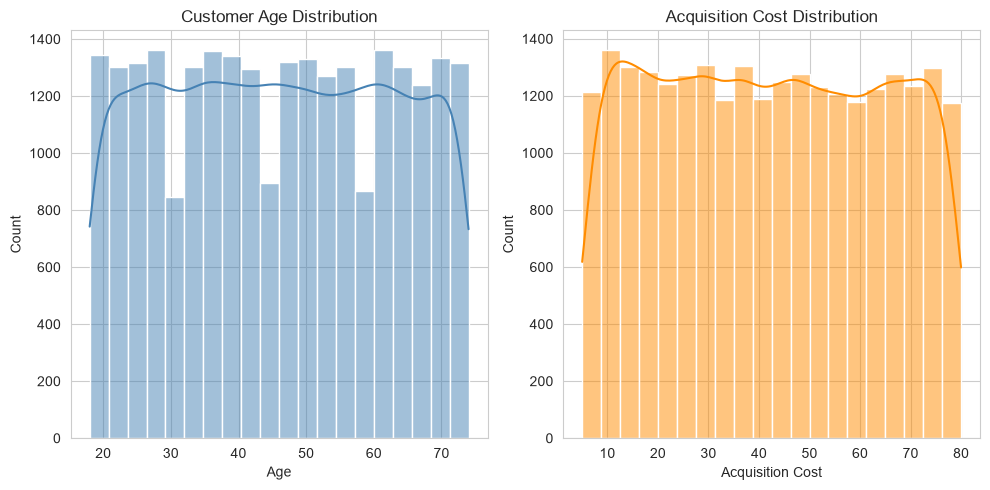

In [6]:
fig, axes =plt.subplots(1,2)

sns.histplot(df["customer_age"], bins= 20, kde= True, ax=axes[0], color="steelblue")
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")

sns.histplot(df["customer_acquisition_cost"], bins= 20, kde= True, ax= axes[1], color="darkorange")
axes[1].set_title("Acquisition Cost Distribution")
axes[1].set_xlabel("Acquisition Cost")

plt.tight_layout()
plt.show()


## 2. Customer Distribution by Gender and Segment

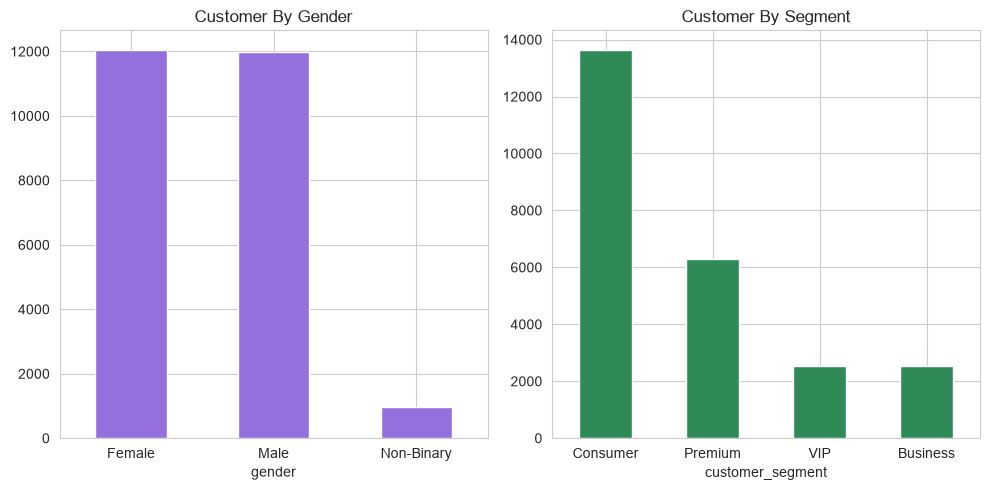

In [7]:
fig, axes =plt.subplots(1,2)

df["gender"].value_counts().plot(kind="bar", ax= axes[0], color= "mediumpurple")
axes[0].set_title("Customer By Gender")
axes[0].tick_params(axis= "x", rotation = 0)

df["customer_segment"].value_counts().plot(kind="bar", ax= axes[1], color= "seagreen")
axes[1].set_title("Customer By Segment")
axes[1].tick_params(axis="x", rotation= 0)

plt.tight_layout()
plt.show()

Conclusion:- The analysis shows that the number of female and male customers is almost equal, while non-binary customers are significantly fever. Among customers segments, Consumers from the largest group, followed by Premium customers, while VIP and Business customers have the lowest numbers.

## 3. Data Integrity & Duplicate Check

In [8]:
unique_ids = df["customer_id"].is_unique
duplicate_rows = df.duplicated().sum()
duplicate_name = df["customer_name"].duplicated().sum()

In [9]:
pd.Series({
    "customer_id is unique": unique_ids,
    "duplicate rows": duplicate_rows,
    "duplicate name" : duplicate_name
})

customer_id is unique    True
duplicate rows              0
duplicate name           3369
dtype: object

Conclusion:- The duplicate check shows that customer_id is unique, so every customer has a distinct ID, and there are 0 duplicate rows, so no record is repeated. There are 3,369 repeated names (about 13.5% of the 25,000 records), but this is expected because different customers can share the same name. Since their IDs and other details differ, these are not true duplicates and no records need to be removed. The data is free of duplicate records and ready for further analysis.

## 4. Customer Summary by Country

In [10]:
country_summary = df.groupby("customer_country").agg(
    customer_count = ("customer_id", "count"),
    avg_age = ("customer_age", "mean"),
    avg_acquisition_cost = ("customer_acquisition_cost", "mean")
).sort_values("customer_count", ascending= False)

country_summary

,customer_count,avg_age,avg_acquisition_cost
customer_country,,,
USA,14925,45.928777,42.085881
UK,3701,45.883545,42.274712
Germany,2046,45.640762,42.217571
Canada,1279,46.275215,42.612651
Australia,1233,45.689376,42.972758
India,1041,46.024976,41.831585
UAE,775,45.909677,41.280594


Conclusion:- The data covers 25,000 customers across 7 countries. The USA is by far the largest market with 14,925 customers (about 60%), followed by the UK (3,701), Germany (2,046) and Canada (1,279). Australia, India and UAE are the smallest markets, with UAE the lowest at 775 customers (about 3%). Average customer age is almost the same everywhere (about 45.6 to 46.3 years), so age does not differ by country. Average acquisition cost is also similar, ranging from about 41.28 in UAE to 42.97 in Australia. Customer volume is concentrated in the USA, while the cost to acquire a customer is nearly the same in every country.

## 5. Average Customer Acquisition Cost by Country

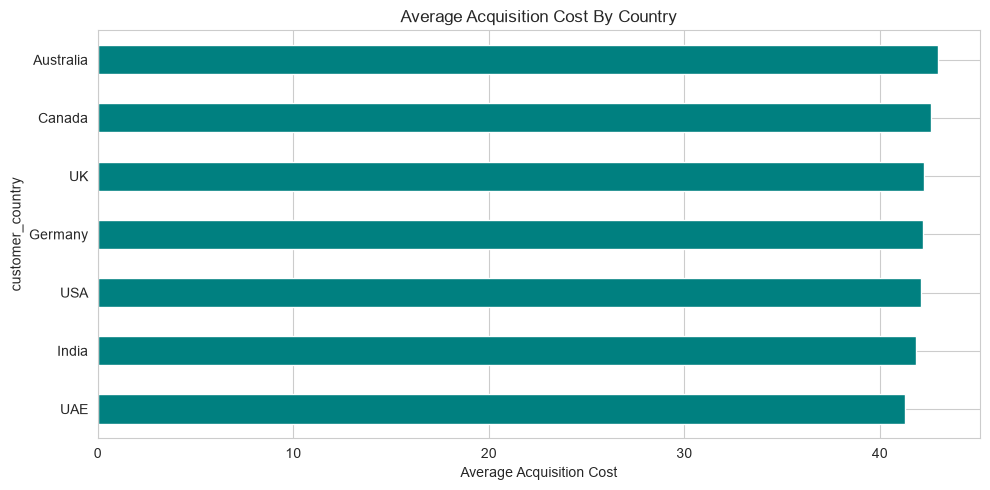

In [11]:
country_summary["avg_acquisition_cost"].sort_values().plot(kind="barh", color= "teal")
plt.title("Average Acquisition Cost By Country")
plt.xlabel("Average Acquisition Cost")
plt.tight_layout()
plt.show()

Conclusion:- The chart shows that average customer acquisition cost is almost the same in every country, ranging from about 41.3 to 43. Australia has the highest cost (about 43), followed by Canada, UK, Germany and USA (all around 42 to 42.6). India and UAE have the lowest costs, with UAE the lowest (about 41.3). The gap between the highest and lowest country is only about 1.7 (roughly 4%), so country has very little effect on acquisition cost. Spending to acquire a customer is nearly uniform worldwide, and no country is clearly cheaper or more expensive to acquire customers from.

## 6. Gender Distribution Across Customer Segments

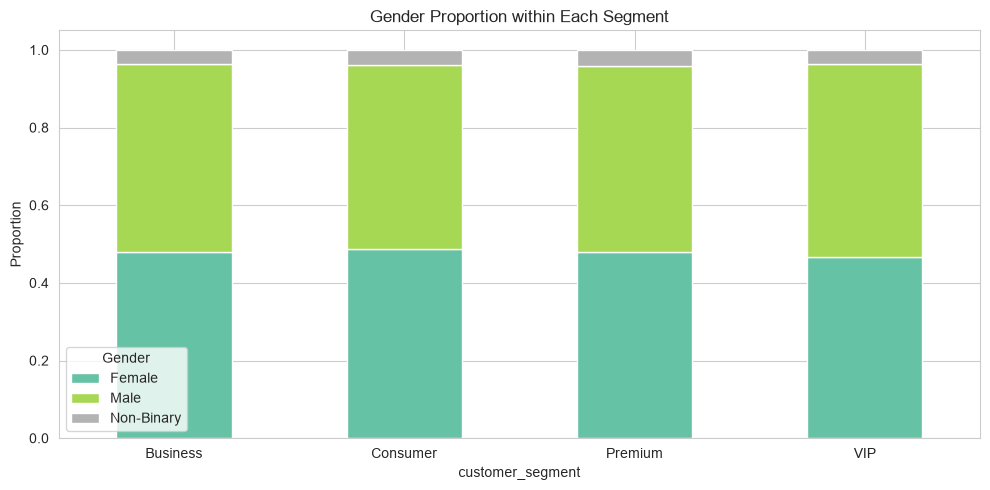

In [12]:
segment_gender = pd.crosstab(df["customer_segment"], df["gender"], normalize= "index")
segment_gender.plot(kind="bar", stacked=True, colormap="Set2")
plt.title("Gender Proportion within Each Segment")
plt.ylabel("Proportion")
plt.xticks(rotation= 0)
plt.legend(title = "Gender")
plt.tight_layout()
plt.show()

Conclusion:- The chart shows that the gender mix is almost the same in all four customer segments (Business, Consumer, Premium and VIP). Female and male customers each make up about 47% to 49% of every segment, and Non-Binary customers make up about 4%. VIP has slightly fewer female customers (about 47%) and slightly more male customers (about 50%), but the difference is very small. Gender does not differ across segments, so it is not a useful factor for separating them.

## 7. Customer Acquisition Cost Matrix: Region by Segment

In [21]:
pivot = df.pivot_table(
    values= "customer_acquisition_cost",
    index= "region",
    columns= "customer_segment",
    aggfunc= "mean"
)

pivot

customer_segment,Business,Consumer,Premium,VIP
region,,,,
Central,42.665208,42.381241,42.033338,40.903996
East,41.582421,41.498164,42.068956,43.113654
North,43.024669,42.521355,42.938065,39.870359
South,42.419132,42.260161,41.927955,42.680490
West,42.257776,42.587711,41.129324,42.167195


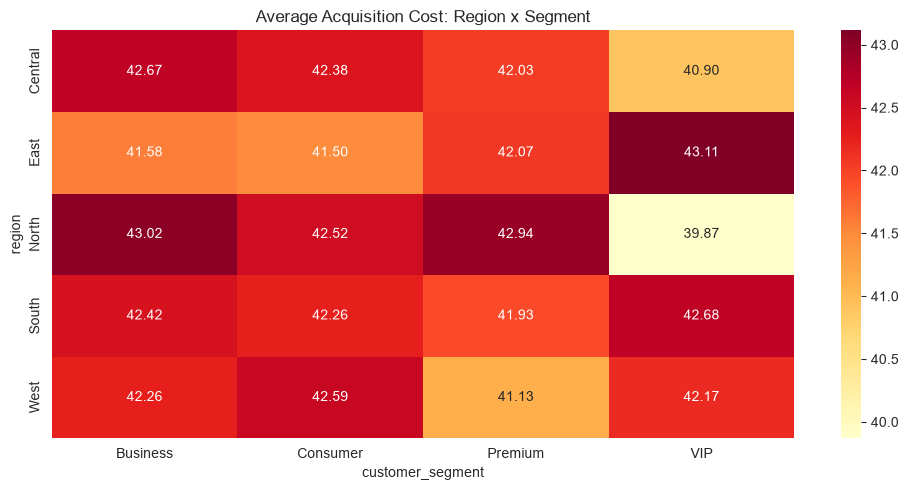

In [29]:
sns.heatmap(pivot, annot= True, fmt=".2f", cmap= 'YlOrRd')
plt.title("Average Acquisition Cost: Region x Segment")
plt.title("Average Acquisition Cost: Region x Segment")
plt.tight_layout()
plt.show()

Conclusion:- The heatmap shows that average acquisition cost stays in a narrow range of about 40 to 43 across all region and segment combinations, so cost does not change much by region or segment. The highest costs are East VIP (43.11), North Business (43.02) and North Premium (42.94), and the lowest are North VIP (39.87), Central VIP (40.90) and West Premium (41.13). VIP customers show the biggest variation by region, being the most expensive to acquire in the East and the cheapest in the North. The Consumer segment is the most consistent (about 41.5 to 42.6 in every region). Overall, acquisition cost is fairly even, and only a few region and segment pairs, mainly VIP in the East and North, differ noticeably.

## 8. Postal Code Length Audit

In [31]:
df["postal_len"] = df["customer_postal_code"].astype(str).str.len()
postal_by_country = pd.crosstab(df["customer_country"], df["postal_len"])

In [32]:
postal_by_country

postal_len,3,4,5
customer_country,,,
Australia,6,106,1121
Canada,7,124,1148
Germany,7,183,1856
India,2,91,948
UAE,3,56,716
UK,19,324,3358
USA,80,1368,13477


Conclusion:- The postal code length check shows that about 90.5% of the 25,000 records (22,624) have 5-digit postal codes, about 9.0% (2,252) have 4 digits and only 0.5% (124) have 3 digits. The same pattern appears in every country, and the USA has the most records in each length group because it is the largest market. The 3- and 4-digit codes are most likely 5-digit codes that lost their leading zeros when stored as numbers, so they are not true errors. Postal codes should be treated as text and padded to 5 digits (for example with `zfill(5)`) to keep the format consistent.

## 9. Mapping Customer Footprint Across Key Countries and Regions

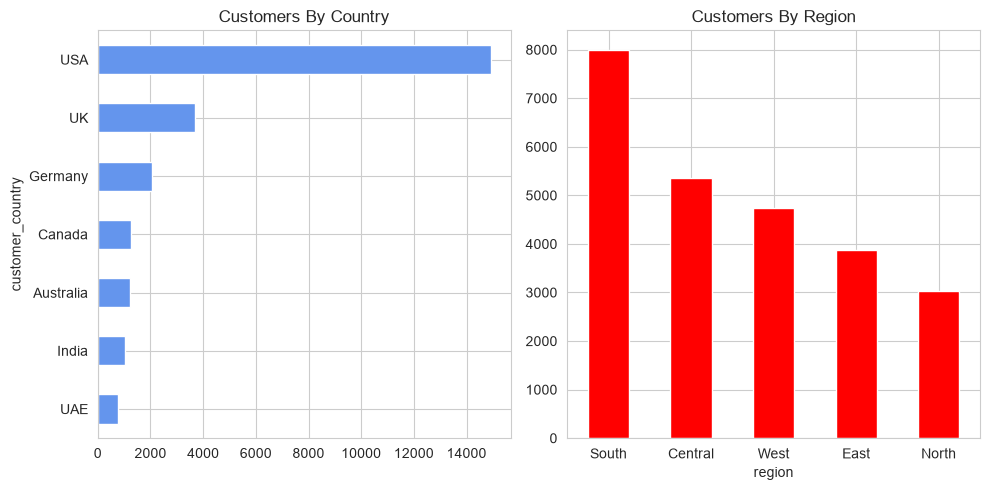

In [35]:
fig, axes = plt.subplots(1, 2)

df["customer_country"].value_counts().plot(kind= "barh", ax= axes[0], color = "cornflowerblue")
axes[0].set_title("Customers By Country")
axes[0].invert_yaxis()

df["region"].value_counts().plot(kind= "bar", ax= axes[1], color="red")
axes[1].set_title("Customers By Region")
axes[1].tick_params(axis= "x", rotation = 0)

plt.tight_layout()
plt.show()

Conclusion:- The charts show that customers are heavily concentrated in a few places. By country, the USA is by far the largest market with about 14,900 customers, followed by the UK (about 3,700) and Germany (about 2,000), while Canada, Australia, India and UAE each have fewer than 1,300 customers. By region, South has the most customers (about 8,000), followed by Central (about 5,300), West (about 4,700) and East (about 3,900), with North the lowest (about 3,000). The business depends mainly on the USA and the South region, so these are the key markets to protect, while the smaller countries and the North region offer room for growth.

## 10. Proportion of VIP Customers by Country

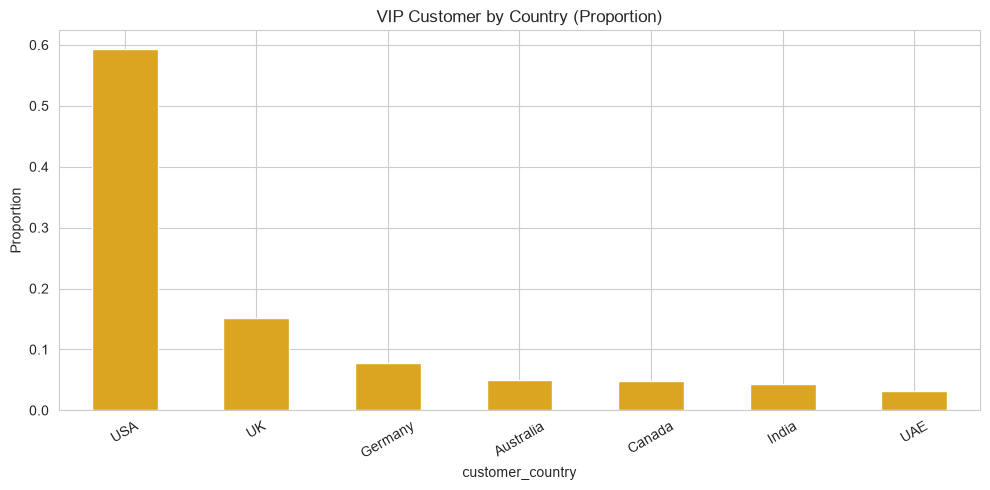

In [36]:
vip_by_country = df[df["customer_segment"] == "VIP"]["customer_country"].value_counts(normalize=True)

vip_by_country.plot(kind= "bar", color= "goldenrod")
plt.title("VIP Customer by Country (Proportion)")
plt.ylabel("Proportion")
plt.xticks(rotation= 30)
plt.tight_layout()
plt.show()

Conclusion:- The chart shows that VIP customers are heavily concentrated in the USA, which accounts for about 59% of all VIP customers. The UK is second (about 15%) and Germany third (about 8%), while Australia, Canada, India and UAE each contribute only about 3% to 5%, with UAE the lowest. This closely matches the overall customer distribution by country, so no country has an unusually high or low share of VIP customers. The USA dominates VIP customers simply because it is the largest customer market.